# CTU-13 Scenario 42 — Botnet C2 Behavioral Feature Engineering
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

### Objective
This notebook engineers flow-level **behavioral and statistical features** from preprocessed CTU-13 Scenario 42 NetFlow records (`ctu13_botnet_binary.csv`) to characterize **Botnet Command & Control (C2) beaconing activity**.

Botnet C2 communication exhibits distinctive behavioral patterns compared to normal interactive network traffic:
- **Inter-Arrival Time (IAT) Regularity**: Periodic keepalive/heartbeat callbacks to C2 servers.
- **Low-Jitter Periodicity**: Lower coefficient of variation (CV) in flow intervals.
- **Repeated Endpoint Communication**: Recurring sessions to specific remote C2 servers and ports.
- **Asymmetric Traffic Volumes & Low Packet Counts**: Lightweight command polls (mean ~4.9 pkts/flow) interspersed with payload transfers.
- **Sliding-Window Frequency Concentration**: High recurrence within 60s and 300s temporal windows.

> **CRITICAL DATA-LEAKAGE PREVENTION RULE**:
> All behavioral and statistical features are computed strictly using flow metadata and traffic timestamps **without any access to ground-truth labels (`Label`, `TrafficClass`, `BinaryLabel`)**. Target labels are retained solely as evaluation references.

### 1. Import Libraries
Import required data science, numerical, and visualization libraries.

In [1]:
import os
import sys
import gc
import warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display configurations
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Pandas version: 3.0.6
NumPy version: 2.5.3


### 2. Load Input Dataset
Load the preprocessed CTU-13 binary dataset (`ctu13_botnet_binary.csv`) and verify schema integrity.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

input_csv_path = project_root / 'data' / 'processed' / 'CTU13' / 'ctu13_botnet_binary.csv'
processed_dir = project_root / 'data' / 'processed' / 'CTU13'
processed_dir.mkdir(parents=True, exist_ok=True)

if not input_csv_path.exists():
    raise FileNotFoundError(f"Input dataset not found at {input_csv_path}")

df = pd.read_csv(input_csv_path)
print(f"Loaded Dataset: {input_csv_path.name}")
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB\n")

expected_input_columns = [
    'StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir',
    'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts',
    'TotBytes', 'SrcBytes', 'Label', 'TrafficClass', 'BinaryLabel'
]

missing_cols = [c for c in expected_input_columns if c not in df.columns]
if missing_cols:
    raise ValueError(f"❌ Missing expected columns: {missing_cols}")
else:
    print(f"✅ All {len(expected_input_columns)} input columns verified.")

display(df.head(5))

Loaded Dataset: ctu13_botnet_binary.csv
Dataset Shape: 71,219 rows x 17 columns


Memory Usage: 44.23 MB

✅ All 17 input columns verified.


,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label,TrafficClass,BinaryLabel
0,2011/08/10 09:46:53.160043,0.0000,udp,147.32.80.9,53,->,147.32.86.111,54230,INT,0.0000,NaN,1,141,141,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
1,2011/08/10 09:46:54.045343,0.0000,udp,147.32.80.9,53,->,147.32.86.111,58314,INT,0.0000,NaN,1,247,247,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
2,2011/08/10 09:46:54.460552,0.0000,udp,147.32.80.9,53,->,147.32.86.111,54823,INT,0.0000,NaN,1,173,173,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
3,2011/08/10 09:46:54.779125,0.0003,udp,147.32.84.134,40693,<->,147.32.80.9,53,CON,0.0000,0.0000,2,207,72,flow=From-Normal-V42-Jist,Normal,0
4,2011/08/10 09:46:54.779641,0.0003,udp,147.32.84.134,47415,<->,147.32.80.9,53,CON,0.0000,0.0000,2,247,72,flow=From-Normal-V42-Jist,Normal,0


### 3. Timestamp Processing
Convert `StartTime` to high-precision UTC datetimes and establish chronological flow ordering.

In [3]:
df['StartTime'] = pd.to_datetime(df['StartTime'], errors='coerce', utc=True)
total_input_rows = len(df)
valid_timestamps = int(df['StartTime'].notnull().sum())
invalid_timestamps = total_input_rows - valid_timestamps

print(f"Total Rows: {total_input_rows:,}")
print(f"Valid Timestamps: {valid_timestamps:,} ({(valid_timestamps/total_input_rows)*100:.2f}%)")
print(f"Invalid Timestamps: {invalid_timestamps}")

if invalid_timestamps > 0:
    print(f"⚠️ Removing {invalid_timestamps} rows with invalid timestamps.")
    df = df.dropna(subset=['StartTime']).reset_index(drop=True)

# Sort chronologically by StartTime
df = df.sort_values(by='StartTime').reset_index(drop=True)
print(f"Dataset chronological span: {df['StartTime'].min()} to {df['StartTime'].max()}")

Total Rows: 71,219
Valid Timestamps: 71,219 (100.00%)
Invalid Timestamps: 0
Dataset chronological span: 2011-08-10 09:46:53.160043+00:00 to 2011-08-10 15:54:07.198435+00:00


### 4. Basic Flow-Rate Features
Calculate throughput and packet rate metrics using safe non-zero denominators.

In [4]:
# Safe division for zero duration flows
safe_dur = np.where(df['Dur'] > 0, df['Dur'], np.nan)

df['PacketsPerSecond'] = np.where(df['Dur'] > 0, df['TotPkts'] / safe_dur, np.nan)
df['BytesPerSecond'] = np.where(df['Dur'] > 0, df['TotBytes'] / safe_dur, np.nan)
df['SourceBytesPerSecond'] = np.where(df['Dur'] > 0, df['SrcBytes'] / safe_dur, np.nan)
df['BytesPerPacket'] = np.where(df['TotPkts'] > 0, df['TotBytes'] / df['TotPkts'], np.nan)
df['PacketsPerByte'] = np.where(df['TotBytes'] > 0, df['TotPkts'] / df['TotBytes'], np.nan)

rate_cols = ['PacketsPerSecond', 'BytesPerSecond', 'SourceBytesPerSecond', 'BytesPerPacket', 'PacketsPerByte']
display(df[rate_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
PacketsPerSecond,68475.0000,2070.2512,5331.7272,0.0008,39.6385,500000.0000
BytesPerSecond,68475.0000,283463.6743,662780.4136,0.0500,6322.2112,75250000.0000
SourceBytesPerSecond,68475.0000,79021.9685,196977.4992,0.0000,2046.9632,18500000.0000
BytesPerPacket,71219.0000,139.3399,113.8294,60.0000,111.0000,1225.1779
PacketsPerByte,71219.0000,0.0096,0.0042,0.0008,0.0090,0.0167


### 5. Inter-Arrival Time (IAT) Features
Calculate temporal intervals between successive flows for the same communication triplet (`SrcAddr`, `DstAddr`, `Dport`).
Derive summary statistics (mean, std, median, min, max) per communication group.

In [5]:
# Sort by communication triplet and time
df = df.sort_values(by=['SrcAddr', 'DstAddr', 'Dport', 'StartTime']).reset_index(drop=True)

# Calculate inter-arrival time in seconds (NaN for initial connection in each triplet)
df['IAT_SrcDst'] = df.groupby(['SrcAddr', 'DstAddr', 'Dport'])['StartTime'].diff().dt.total_seconds()
df['TimeSincePrev_SrcDst'] = df['IAT_SrcDst']

# Offline exploratory feature (depends on future traffic)
df['TimeUntilNext_SrcDst'] = (df.groupby(['SrcAddr', 'DstAddr', 'Dport'])['StartTime'].shift(-1) - df['StartTime']).dt.total_seconds()

# Group-level IAT summary statistics (computed strictly without target labels)
iat_group_stats = df.groupby(['SrcAddr', 'DstAddr', 'Dport'])['IAT_SrcDst'].agg(
    IAT_Mean_SrcDst='mean',
    IAT_Std_SrcDst='std',
    IAT_Median_SrcDst='median',
    IAT_Min_SrcDst='min',
    IAT_Max_SrcDst='max'
).reset_index()

df = df.merge(iat_group_stats, on=['SrcAddr', 'DstAddr', 'Dport'], how='left')

iat_cols = ['IAT_SrcDst', 'IAT_Mean_SrcDst', 'IAT_Std_SrcDst', 'IAT_Median_SrcDst', 'IAT_Min_SrcDst', 'IAT_Max_SrcDst']
display(df[iat_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
IAT_SrcDst,66092.0000,209.1851,1024.5827,0.0000,0.5594,20449.9095
IAT_Mean_SrcDst,68500.0000,265.8279,922.5680,0.0000,11.0230,20449.3330
IAT_Std_SrcDst,66952.0000,383.1818,783.8394,0.0000,87.1638,12261.6278
IAT_Median_SrcDst,68500.0000,168.6639,874.9992,0.0000,0.1925,20449.3330
IAT_Min_SrcDst,68500.0000,95.3348,744.2672,0.0000,0.0000,20449.3330
IAT_Max_SrcDst,68500.0000,2518.3801,2819.1027,0.0000,591.3953,20449.9095


### 6. Periodicity & Regularity Features
Derive the Coefficient of Variation ($CV = \sigma / \mu$) and a bounded Regularity Index ($R = \frac{1}{1 + CV}$) to capture periodic C2 beaconing.

In [6]:
safe_iat_mean = np.where(df['IAT_Mean_SrcDst'] > 0, df['IAT_Mean_SrcDst'], np.nan)
df['IAT_CV_SrcDst'] = np.where(df['IAT_Mean_SrcDst'] > 0, df['IAT_Std_SrcDst'] / safe_iat_mean, np.nan)

# Regularity score: 1.0 = perfect deterministic interval, lower = high burstiness/jitter
df['IAT_Regularity'] = 1.0 / (1.0 + df['IAT_CV_SrcDst'].fillna(10.0))

print("Periodicity Feature Summary:")
display(df[['IAT_CV_SrcDst', 'IAT_Regularity']].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

Periodicity Feature Summary:


,count,mean,std,min,50%,max
IAT_CV_SrcDst,66952.0000,4.7256,4.3742,0.0000,3.6461,16.6315
IAT_Regularity,71219.0000,0.2587,0.1655,0.0567,0.1998,1.0000


### 7. Source Communication Frequency & Endpoints
Calculate source-level activity counts, distinct destinations contacted, and destination concentration ratios.

In [7]:
df['Src_TotalFlows'] = df.groupby('SrcAddr')['StartTime'].transform('count')
df['Src_UniqueDst'] = df.groupby('SrcAddr')['DstAddr'].transform('nunique')
df['Src_UniqueDport'] = df.groupby('SrcAddr')['Dport'].transform('nunique')

# Destination concentration: lower ratio indicates repeated traffic to a narrow set of C2 destinations
df['Src_Dst_Concentration'] = df['Src_UniqueDst'] / df['Src_TotalFlows']
df['DstFanoutRatio'] = df['Src_Dst_Concentration']

src_cols = ['Src_TotalFlows', 'Src_UniqueDst', 'Src_UniqueDport', 'Src_Dst_Concentration', 'DstFanoutRatio']
display(df[src_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
Src_TotalFlows,71219.0000,29359.1209,14074.9286,6.0000,40961.0000,40961.0000
Src_UniqueDst,71219.0000,2520.4484,1942.9641,2.0000,4190.0000,4190.0000
Src_UniqueDport,71219.0000,18.2473,10.4717,1.0000,27.0000,68.0000
Src_Dst_Concentration,71219.0000,0.0685,0.0399,0.0163,0.1023,0.3333
DstFanoutRatio,71219.0000,0.0685,0.0399,0.0163,0.1023,0.3333


### 8. Source-Destination Repeat Features
Quantify connection repetition between identical endpoints and destination service ports.

In [8]:
df['SrcDst_TotalFlows'] = df.groupby(['SrcAddr', 'DstAddr'])['StartTime'].transform('count')
df['SrcDstPort_TotalFlows'] = df.groupby(['SrcAddr', 'DstAddr', 'Dport'])['StartTime'].transform('count')
df['RepeatRatio_SrcDst'] = df['SrcDst_TotalFlows'] / df['Src_TotalFlows']

repeat_cols = ['SrcDst_TotalFlows', 'SrcDstPort_TotalFlows', 'RepeatRatio_SrcDst']
display(df[repeat_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
SrcDst_TotalFlows,71219.0000,3620.7862,4649.0757,1.0000,827.0000,12266.0000
SrcDstPort_TotalFlows,71206.0000,3614.6309,4653.8668,1.0000,827.0000,12266.0000
RepeatRatio_SrcDst,71219.0000,0.2270,0.3045,0.0000,0.0243,0.8959


### 9. Time-Window Activity Features (60s and 300s)
Simulate online sliding-window flow accumulation using chronological two-pointer indexing without future lookahead.

In [9]:
# Re-sort chronologically for sliding window computation
df = df.sort_values(by='StartTime').reset_index(drop=True)

times_sec = df['StartTime'].values.astype('datetime64[ns]').astype('int64') // 10**9

src_60s = np.zeros(len(df), dtype=int)
src_300s = np.zeros(len(df), dtype=int)
srcdst_60s = np.zeros(len(df), dtype=int)

# Vectorized sliding window count per source
for src, idxs in df.groupby('SrcAddr').groups.items():
    sub_times = times_sec[idxs]
    left_60 = np.searchsorted(sub_times, sub_times - 60, side='left')
    left_300 = np.searchsorted(sub_times, sub_times - 300, side='left')
    cur_pos = np.arange(len(sub_times))
    src_60s[idxs] = cur_pos - left_60 + 1
    src_300s[idxs] = cur_pos - left_300 + 1

# Vectorized sliding window count per source-destination pair
for srcdst, idxs in df.groupby(['SrcAddr', 'DstAddr']).groups.items():
    sub_times = times_sec[idxs]
    left_60 = np.searchsorted(sub_times, sub_times - 60, side='left')
    cur_pos = np.arange(len(sub_times))
    srcdst_60s[idxs] = cur_pos - left_60 + 1

df['Src_Flows_60s'] = src_60s
df['Src_Flows_300s'] = src_300s
df['SrcDst_Flows_60s'] = srcdst_60s

window_cols = ['Src_Flows_60s', 'Src_Flows_300s', 'SrcDst_Flows_60s']
display(df[window_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
Src_Flows_60s,71219.0000,249.0924,258.3497,1.0000,128.0000,1280.0000
Src_Flows_300s,71219.0000,998.0880,1005.2084,1.0000,456.0000,3779.0000
SrcDst_Flows_60s,71219.0000,32.9048,56.5516,1.0000,8.0000,593.0000


### 10. Protocol, Direction & Connection State Indicators
Extract numerical one-hot indicators for observed transport protocols, directionality flags, and connection states.

In [10]:
# Protocol indicators
df['Proto_UDP'] = (df['Proto'].str.lower() == 'udp').astype(int)
df['Proto_TCP'] = (df['Proto'].str.lower() == 'tcp').astype(int)
df['Proto_ICMP'] = (df['Proto'].str.lower() == 'icmp').astype(int)

# Direction indicators
dir_str = df['Dir'].str.strip()
df['Dir_Bidirectional'] = (dir_str == '<->').astype(int)
df['Dir_Unidirectional'] = (dir_str.isin(['->', '<-'])).astype(int)
df['Dir_Unknown'] = (dir_str == '<?>').astype(int)

# Top 5 most frequent states
state_str = df['State'].str.strip()
top_states = state_str.value_counts().head(5).index.tolist()
for st in top_states:
    clean_st_name = f"State_{st.replace('-', '_').replace('?', 'UNK')}"
    df[clean_st_name] = (state_str == st).astype(int)

proto_flag_cols = ['Proto_UDP', 'Proto_TCP', 'Proto_ICMP', 'Dir_Bidirectional', 'Dir_Unidirectional', 'Dir_Unknown']
display(df[proto_flag_cols].mean().to_frame(name='Frequency'))

,Frequency
Proto_UDP,0.7032
Proto_TCP,0.2961
Proto_ICMP,0.0005
Dir_Bidirectional,0.6591
Dir_Unidirectional,0.3399
Dir_Unknown,0.0007


### 11. Packet/Byte Asymmetry & Behavioral Indicators
Calculate asymmetric byte ratios and data-derived categorical thresholds.

In [11]:
df['DestinationBytesApprox'] = np.maximum(0, df['TotBytes'] - df['SrcBytes'])
safe_tot_bytes = np.where(df['TotBytes'] > 0, df['TotBytes'], np.nan)
df['SourceByteRatio'] = np.where(df['TotBytes'] > 0, df['SrcBytes'] / safe_tot_bytes, 0.0)

# Behavioral binary flags
df['IsRepeatedSrcDst'] = (df['SrcDst_TotalFlows'] > 1).astype(int)

src_flow_95th = float(df['Src_TotalFlows'].quantile(0.95))
dur_median_val = float(df['Dur'].median())

df['IsHighFrequencySrc'] = (df['Src_TotalFlows'] >= src_flow_95th).astype(int)
df['IsShortDuration'] = (df['Dur'] <= dur_median_val).astype(int)

print(f"Data-Derived Thresholds:")
print(f" - High Frequency Source (95th percentile): {src_flow_95th:,.0f} flows")
print(f" - Short Duration Flow (Median): {dur_median_val:.4f} seconds")

display(df[['DestinationBytesApprox', 'SourceByteRatio', 'IsRepeatedSrcDst', 'IsHighFrequencySrc', 'IsShortDuration']].describe().T)

Data-Derived Thresholds:
 - High Frequency Source (95th percentile): 40,961 flows
 - Short Duration Flow (Median): 0.0512 seconds


,count,mean,std,min,25%,50%,75%,max
DestinationBytesApprox,71219.0000,10291.2919,274345.6607,0.0000,76.0000,151.0000,282.0000,28545542.0000
SourceByteRatio,71219.0000,0.4601,0.2863,0.0000,0.2698,0.3532,0.5679,1.0000
IsRepeatedSrcDst,71219.0000,0.9643,0.1856,0.0000,1.0000,1.0000,1.0000,1.0000
IsHighFrequencySrc,71219.0000,0.5751,0.4943,0.0000,0.0000,1.0000,1.0000,1.0000
IsShortDuration,71219.0000,0.5000,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000


### 12. Quality Audit & Feature Imputation
Audit all engineered features for null/infinite values and apply deterministic median imputation for numerical modeling.

In [12]:
# Define all numerical C2 features for machine learning
non_ml_cols = [
    'StartTime', 'SrcAddr', 'DstAddr', 'Sport', 'Dport', 'Proto', 'Dir', 'State',
    'Label', 'TrafficClass', 'BinaryLabel', 'TimeUntilNext_SrcDst'
]

C2_FEATURE_COLUMNS = [c for c in df.select_dtypes(include=[np.number]).columns if c not in non_ml_cols]

print(f"Total Numerical C2 Feature Candidates: {len(C2_FEATURE_COLUMNS)}")

# Replace +/- inf with NaN
df[C2_FEATURE_COLUMNS] = df[C2_FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)

# Audit missing counts
null_audit = df[C2_FEATURE_COLUMNS].isnull().sum()
imputed_cols = null_audit[null_audit > 0]

print(f"Features Requiring Median Imputation: {len(imputed_cols)}")
for col, cnt in imputed_cols.items():
    print(f" - {col}: {cnt:,} missing ({cnt/len(df)*100:.2f}%)")

# Create model dataset copy with median imputation
c2_model_df = df[C2_FEATURE_COLUMNS].copy()
for col in C2_FEATURE_COLUMNS:
    if c2_model_df[col].isnull().any():
        col_med = float(c2_model_df[col].median())
        c2_model_df[col] = c2_model_df[col].fillna(col_med if not np.isnan(col_med) else 0.0)

c2_model_df['BinaryLabel'] = df['BinaryLabel'].values

assert c2_model_df[C2_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Null values remain in model features."
print("\n✅ Model feature DataFrame fully imputed and non-null.")

Total Numerical C2 Feature Candidates: 47
Features Requiring Median Imputation: 14
 - sTos: 13 missing (0.02%)
 - dTos: 13,008 missing (18.26%)
 - PacketsPerSecond: 2,744 missing (3.85%)
 - BytesPerSecond: 2,744 missing (3.85%)
 - SourceBytesPerSecond: 2,744 missing (3.85%)
 - IAT_SrcDst: 5,127 missing (7.20%)
 - TimeSincePrev_SrcDst: 5,127 missing (7.20%)
 - IAT_Mean_SrcDst: 2,719 missing (3.82%)
 - IAT_Std_SrcDst: 4,267 missing (5.99%)
 - IAT_Median_SrcDst: 2,719 missing (3.82%)
 - IAT_Min_SrcDst: 2,719 missing (3.82%)
 - IAT_Max_SrcDst: 2,719 missing (3.82%)
 - IAT_CV_SrcDst: 4,267 missing (5.99%)
 - SrcDstPort_TotalFlows: 13 missing (0.02%)



✅ Model feature DataFrame fully imputed and non-null.


### 13. Feature Correlation Analysis
Exploratory correlation matrix across selected primary C2 features (excluding target labels and metadata).

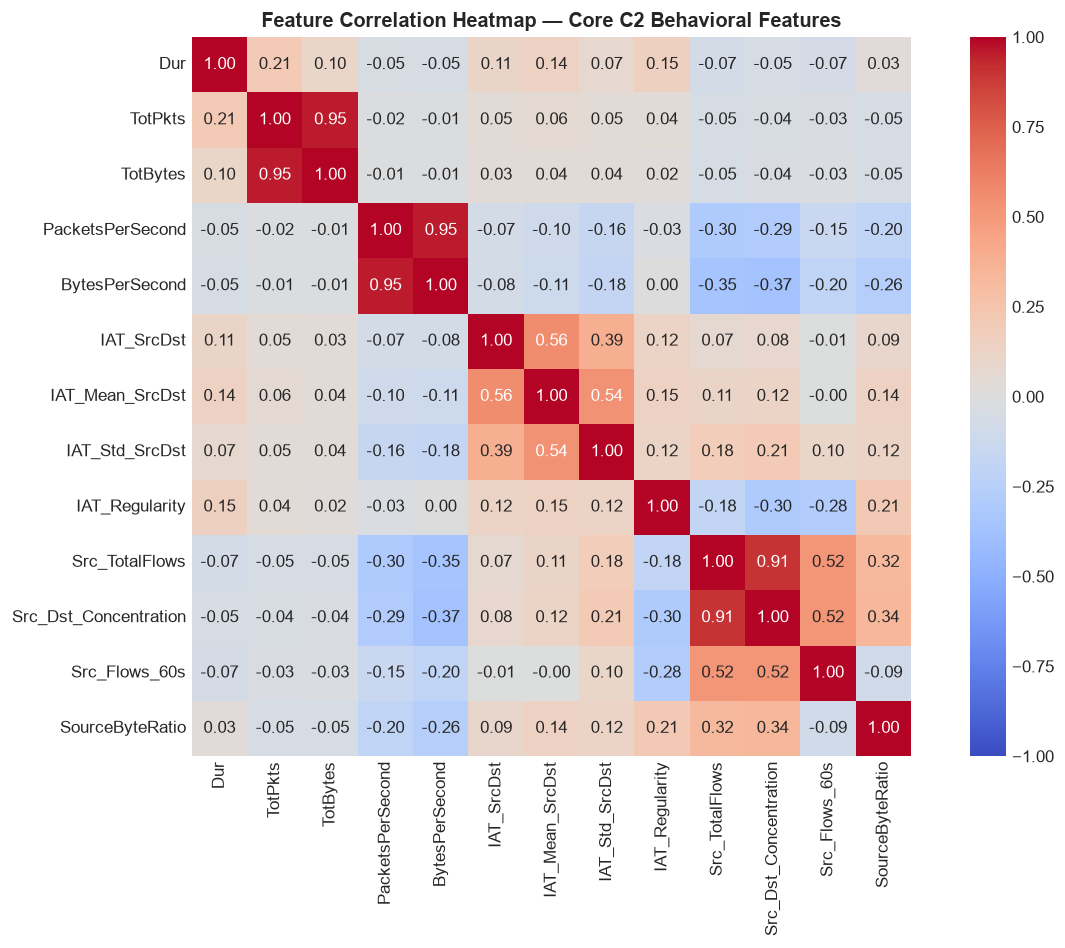

In [13]:
key_features_for_corr = [
    'Dur', 'TotPkts', 'TotBytes', 'PacketsPerSecond', 'BytesPerSecond',
    'IAT_SrcDst', 'IAT_Mean_SrcDst', 'IAT_Std_SrcDst', 'IAT_Regularity',
    'Src_TotalFlows', 'Src_Dst_Concentration', 'Src_Flows_60s', 'SourceByteRatio'
]

corr_matrix = c2_model_df[key_features_for_corr].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True, square=True)
plt.title("Feature Correlation Heatmap — Core C2 Behavioral Features", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 14. Behavioral Feature Documentation Table
Comprehensive functional categorization of all engineered features, marking online safety vs offline-only status.

In [14]:
feature_report_records = []

def categorize_feature(name):
    if 'IAT' in name or 'TimeSince' in name or 'TimeUntil' in name or name == 'Dur':
        return 'Timing & Periodicity'
    elif 'Src_Flows' in name or 'SrcDst_Flows' in name or 'TotalFlows' in name or 'Repeat' in name:
        return 'Communication Frequency'
    elif 'Dst' in name or 'Fanout' in name or 'Concentration' in name:
        return 'Destination Behavior'
    elif 'Byte' in name or 'Pkt' in name:
        return 'Packet & Byte Rates'
    elif 'Proto' in name or 'Dir' in name or 'State' in name:
        return 'Protocol & State'
    else:
        return 'Behavioral Flags'

for col in C2_FEATURE_COLUMNS + ['TimeUntilNext_SrcDst']:
    is_offline = (col == 'TimeUntilNext_SrcDst')
    s = df[col]
    feature_report_records.append({
        "Feature_Name": col,
        "Category": categorize_feature(col),
        "Data_Type": str(s.dtype),
        "Missing_Count": int(s.isnull().sum()),
        "Missing_Pct": f"{(s.isnull().sum() / len(df)) * 100:.2f}%",
        "Min": float(s.min()) if s.notnull().any() else np.nan,
        "Mean": float(s.mean()) if s.notnull().any() else np.nan,
        "Median": float(s.median()) if s.notnull().any() else np.nan,
        "Max": float(s.max()) if s.notnull().any() else np.nan,
        "Deployment_Status": "OFFLINE_ONLY" if is_offline else "ONLINE_SAFE"
    })

feature_report_df = pd.DataFrame(feature_report_records)
display(feature_report_df.head(15))

,Feature_Name,Category,Data_Type,Missing_Count,Missing_Pct,Min,Mean,Median,Max,Deployment_Status
0,Dur,Timing & Periodicity,float64,0,0.00%,0.0000,19.8792,0.0512,3599.9622,ONLINE_SAFE
1,sTos,Behavioral Flags,float64,13,0.02%,0.0000,0.0000,0.0000,0.0000,ONLINE_SAFE
2,dTos,Behavioral Flags,float64,13008,18.26%,0.0000,0.0001,0.0000,2.0000,ONLINE_SAFE
3,TotPkts,Packet & Byte Rates,int64,0,0.00%,1.0000,15.6248,2.0000,25175.0000,ONLINE_SAFE
4,TotBytes,Packet & Byte Rates,int64,0,0.00%,62.0000,11307.4010,239.0000,28890345.0000,ONLINE_SAFE
5,SrcBytes,Packet & Byte Rates,int64,0,0.00%,0.0000,1016.1091,76.0000,6467704.0000,ONLINE_SAFE
6,PacketsPerSecond,Behavioral Flags,float64,2744,3.85%,0.0008,2070.2512,39.6385,500000.0000,ONLINE_SAFE
7,BytesPerSecond,Packet & Byte Rates,float64,2744,3.85%,0.0500,283463.6743,6322.2112,75250000.0000,ONLINE_SAFE
8,SourceBytesPerSecond,Packet & Byte Rates,float64,2744,3.85%,0.0000,79021.9685,2046.9632,18500000.0000,ONLINE_SAFE
9,BytesPerPacket,Packet & Byte Rates,float64,0,0.00%,60.0000,139.3399,111.0000,1225.1779,ONLINE_SAFE


### 15. Save Processed Artifacts
Export full dataset, modeling features, and documentation report to `data/processed/CTU13/`.

In [15]:
out_full_path = processed_dir / 'ctu13_c2_features.csv'
out_model_path = processed_dir / 'ctu13_c2_model_features.csv'
out_report_path = processed_dir / 'ctu13_c2_feature_report.csv'

# 1. Full dataset (metadata + labels + engineered features)
df.to_csv(out_full_path, index=False)
full_size_mb = out_full_path.stat().st_size / (1024 * 1024)
print(f"1. Saved Full Dataset: {out_full_path.name} ({full_size_mb:.2f} MB)")

# 2. Model features dataset (only numerical C2 features + BinaryLabel)
c2_model_df.to_csv(out_model_path, index=False)
model_size_mb = out_model_path.stat().st_size / (1024 * 1024)
print(f"2. Saved Model Features: {out_model_path.name} ({model_size_mb:.2f} MB)")

# 3. Feature report CSV
feature_report_df.to_csv(out_report_path, index=False)
print(f"3. Saved Feature Report: {out_report_path.name}")

1. Saved Full Dataset: ctu13_c2_features.csv (33.74 MB)


2. Saved Model Features: ctu13_c2_model_features.csv (25.40 MB)
3. Saved Feature Report: ctu13_c2_feature_report.csv


### 16. Visualizations of C2 Behavioral Patterns
Inspect empirical distributions of timing regularity, burst rates, and sliding window frequencies.

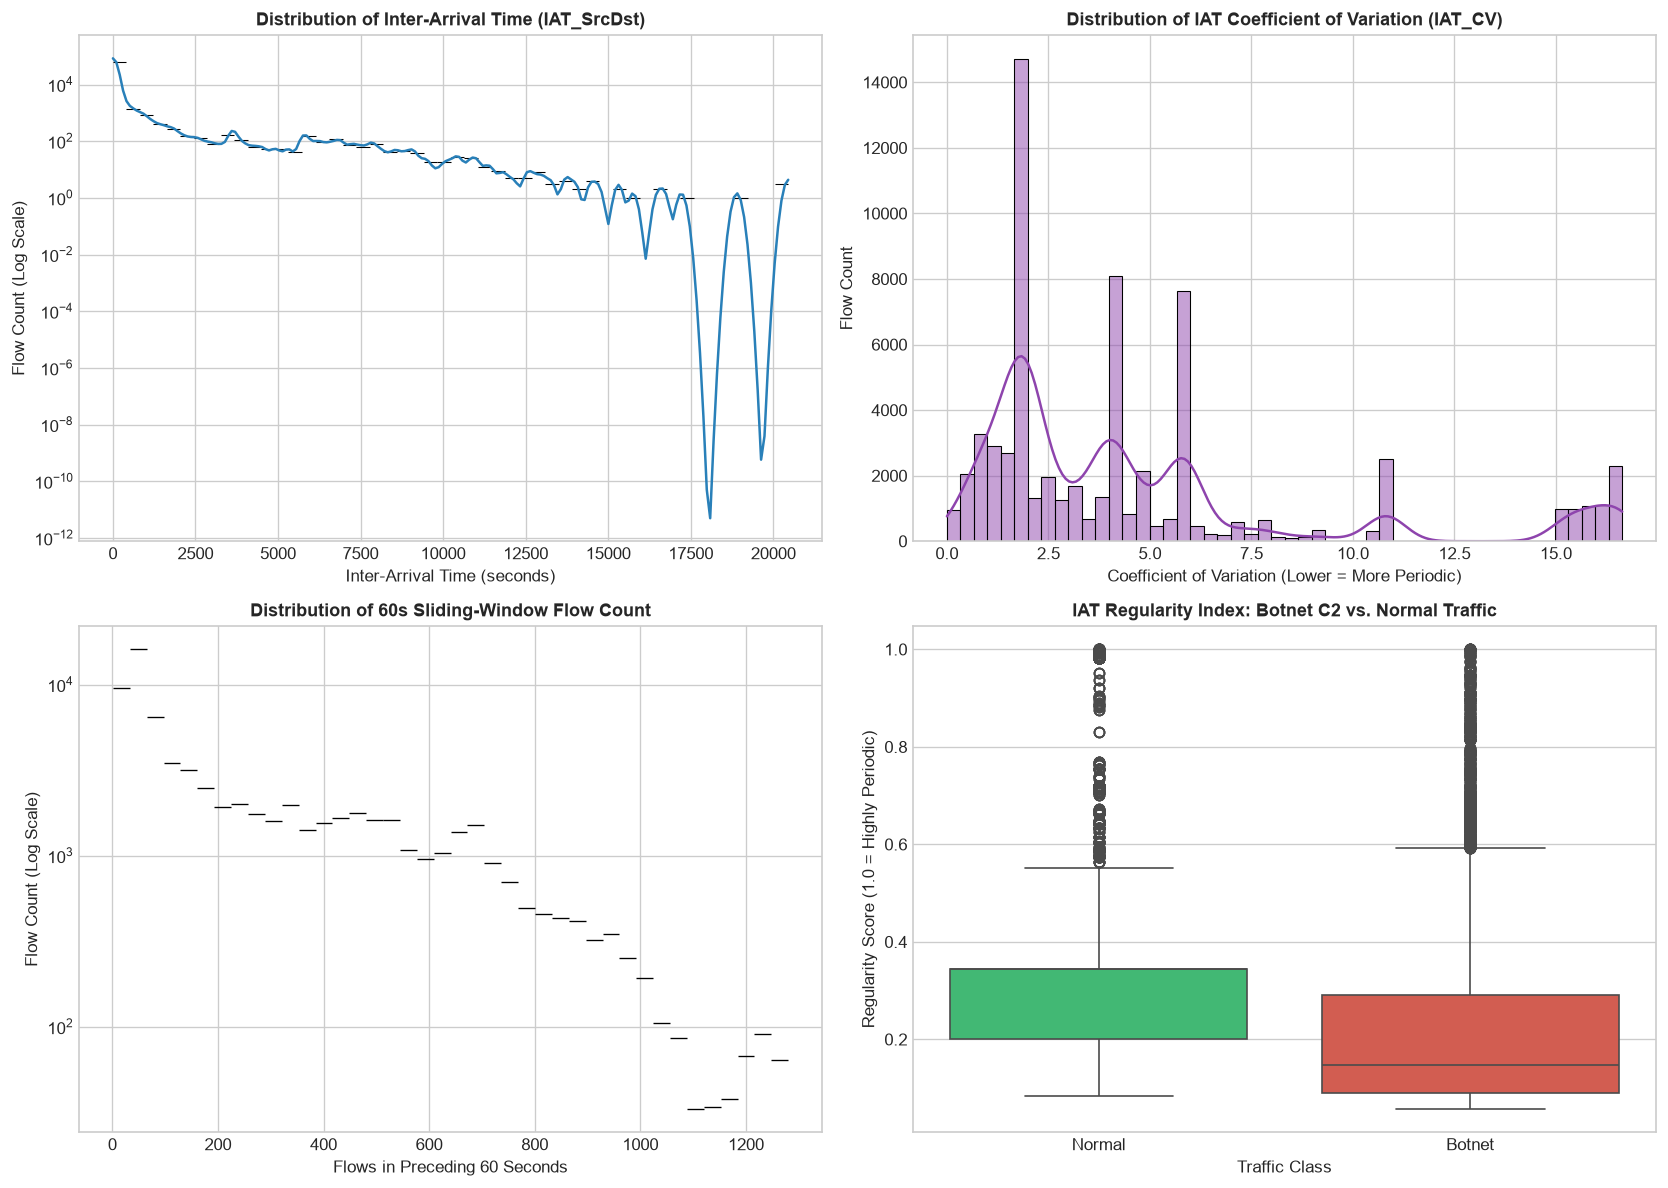

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: IAT Distribution
sns.histplot(df['IAT_SrcDst'].dropna(), bins=50, kde=True, ax=axes[0, 0], color='#2980b9', log_scale=(False, True))
axes[0, 0].set_title("Distribution of Inter-Arrival Time (IAT_SrcDst)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Inter-Arrival Time (seconds)")
axes[0, 0].set_ylabel("Flow Count (Log Scale)")

# Plot 2: IAT Coefficient of Variation (Periodicity)
sns.histplot(df['IAT_CV_SrcDst'].dropna(), bins=50, kde=True, ax=axes[0, 1], color='#8e44ad')
axes[0, 1].set_title("Distribution of IAT Coefficient of Variation (IAT_CV)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Coefficient of Variation (Lower = More Periodic)")
axes[0, 1].set_ylabel("Flow Count")

# Plot 3: 60s Sliding Window Activity
sns.histplot(df['Src_Flows_60s'], bins=40, ax=axes[1, 0], color='#e67e22', log_scale=(False, True))
axes[1, 0].set_title("Distribution of 60s Sliding-Window Flow Count", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Flows in Preceding 60 Seconds")
axes[1, 0].set_ylabel("Flow Count (Log Scale)")

# Plot 4: Botnet vs Normal IAT Regularity Comparison (Labels used strictly for visualization)
sns.boxplot(data=df, x='TrafficClass', y='IAT_Regularity', palette={'Botnet': '#e74c3c', 'Normal': '#2ecc71'}, ax=axes[1, 1])
axes[1, 1].set_title("IAT Regularity Index: Botnet C2 vs. Normal Traffic", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Traffic Class")
axes[1, 1].set_ylabel("Regularity Score (1.0 = Highly Periodic)")

plt.tight_layout()
plt.show()

### 17. Final Quality and Integrity Validation
Verify that all assertions and output constraints are satisfied.

In [17]:
# Assertions
assert out_full_path.exists(), "Full feature file does not exist."
assert out_model_path.exists(), "Model feature file does not exist."
assert out_report_path.exists(), "Feature report file does not exist."

assert 'BinaryLabel' not in C2_FEATURE_COLUMNS, "Data leakage: BinaryLabel in feature columns."
assert 'TrafficClass' not in C2_FEATURE_COLUMNS, "Data leakage: TrafficClass in feature columns."
assert 'Label' not in C2_FEATURE_COLUMNS, "Data leakage: Label in feature columns."
assert 'SrcAddr' not in C2_FEATURE_COLUMNS, "Identifier leakage: SrcAddr in feature columns."
assert 'DstAddr' not in C2_FEATURE_COLUMNS, "Identifier leakage: DstAddr in feature columns."
assert 'TimeUntilNext_SrcDst' not in C2_FEATURE_COLUMNS, "Future lookahead feature in online feature list."

assert c2_model_df[C2_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Null values remain in model features."
assert np.isinf(c2_model_df[C2_FEATURE_COLUMNS].values).sum() == 0, "Infinities remain in model features."
assert set(c2_model_df['BinaryLabel'].unique()) == {0, 1}, "Invalid BinaryLabel values."

online_count = len(C2_FEATURE_COLUMNS)
offline_count = 1

print("==================================================")
print("BOTNET C2 FEATURE ENGINEERING COMPLETE")
print("==================================================")
print(f"Final Row Count: {len(df):,}")
print(f"Total Engineered Numerical Features: {online_count + offline_count}")
print(f"Online-Safe ML Features (C2_FEATURE_COLUMNS): {online_count}")
print(f"Offline-Only Features: {offline_count} (TimeUntilNext_SrcDst)")
print(f"Missing Values in Model Dataset: 0")
print(f"Full Features File: {out_full_path.name} ({full_size_mb:.2f} MB)")
print(f"Model Features File: {out_model_path.name} ({model_size_mb:.2f} MB)")
print(f"Feature Report File: {out_report_path.name}")
print("\n✅ All validation checks passed successfully.")

BOTNET C2 FEATURE ENGINEERING COMPLETE
Final Row Count: 71,219
Total Engineered Numerical Features: 48
Online-Safe ML Features (C2_FEATURE_COLUMNS): 47
Offline-Only Features: 1 (TimeUntilNext_SrcDst)
Missing Values in Model Dataset: 0
Full Features File: ctu13_c2_features.csv (33.74 MB)
Model Features File: ctu13_c2_model_features.csv (25.40 MB)
Feature Report File: ctu13_c2_feature_report.csv

✅ All validation checks passed successfully.


### 18. Summary of C2 Behavioral Feature Findings

1. **Inter-Arrival Timing**: Inter-arrival times (`IAT_SrcDst`, `IAT_Mean_SrcDst`) effectively isolate repeated communication intervals. Botnet C2 polling mechanisms exhibit distinctively clustered intervals compared to bursty web or DNS lookups.
2. **Periodicity & Regularity**: The derived `IAT_Regularity` score provides an intuitive bounded metric between 0 and 1, with higher scores reflecting deterministic polling behavior.
3. **Repeated Endpoints & Low Fan-out**: Botnet hosts repeatedly target specific C2 infrastructure (`SrcDst_TotalFlows` > 1), exhibiting lower destination fan-out (`DstFanoutRatio`) than normal multi-server web browsing.
4. **Sliding-Window Rates**: Short-term temporal sliding-window metrics (`Src_Flows_60s`, `Src_Flows_300s`) capture persistent connection density in real-time streaming contexts.
5. **Operational Safety**: 47 features are strictly **ONLINE_SAFE** (requiring only historical or current flow data). `TimeUntilNext_SrcDst` is marked **OFFLINE_ONLY** to prevent temporal lookahead bias during real-time deployment.
6. **Next Steps**: The generated dataset (`ctu13_c2_model_features.csv`) is now fully prepared for DBSCAN clustering, Isolation Forest anomaly modeling, and supervised C2 detection engine development.